# SymPhase tutorial 17 — magnitudes from Wannier-based Kubo codes, constrained by symmetry

Symmetry fixes the **shape** of a response tensor; the **magnitude** needs a Kubo calculation on a Wannier Hamiltonian.
`symphase kubo` links the two:

| step | what | command |
|---|---|---|
| plan | minimal set of components to compute (+ postw90 input blocks, a check component) | `symphase kubo plan --kind spin` |
| import | postw90 `*-ahc-fermiscan.dat`, `*-shc-fermiscan.dat` (+ `.win`), any `component value` table | `symphase kubo import ...` |
| fit | least-squares fit of the independent parameters → full tensor, violation, forbidden non-zero components | automatic |
| compute | built-in reference Kubo solver on `seedname_hr.dat` (AHC, SHC) for the pivot components only | `symphase kubo compute ...` |

Conventions as in postw90: $\sigma_{ij}=-\frac{e^2}{\hbar}\int\!\sum_n f_n\Omega_{n,ij}$,
$\Omega_{n,ij}=-2\,\mathrm{Im}\sum_{m\ne n}\frac{\langle n|\partial_iH|m\rangle\langle m|\partial_jH|n\rangle}{(E_n-E_m)^2+\eta^2}$; spin: $\partial_iH\to\frac12\{\sigma_k,\partial_iH\}$
(units $\hbar/e$). $J^{S_k}_i=\sigma^k_{ij}E_j$ ↔ postw90 `shc_alpha=i, shc_beta=j, shc_gamma=k`.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import numpy as np, math, os, copy, warnings
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
from symphase import analyze_tensors
from symphase.tensors import read_poscar
from symphase.kubo import (SymTensor, plan, KuboTB, compute_symmetric, format_fit, read_hr, read_centres,
                           read_postw90_ahc, read_postw90_shc, haldane_hr, kane_mele_hr, honeycomb_lattice)
from symphase.qha import quartic_oscillator, AnharmonicF, FreeEnergySurface, QHA
from symphase.thermo import FiniteTHull
from symphase.hull import load_csv
KB = f"{EX}/kubo"
lat, frac = honeycomb_lattice(); cen = frac @ lat
def haldane(M=0.0, phi=math.pi / 2, efs=(0.0,), n=(60, 60)):
    R, H = haldane_hr(M=M, phi=phi)
    return KuboTB(lat, R, H, centres=cen, dims=2).conductivity([("charge", 0, 0, 1)], list(efs), n, 1e-6)[:, 0]
def kane_mele(efs=(0.0,), n=(60, 60)):
    R, H = kane_mele_hr()
    return KuboTB(lat, R, H, centres=np.r_[cen, cen], dims=2, spin_order="blocks").conductivity(
        [("spin", 2, 0, 1), ("charge", 0, 0, 1)], list(efs), n, 1e-6)
scph_csv = f"{EX}/hull/NiAl_scph.csv"

## 1. Plan: what must postw90 compute for fcc Pt?

In [3]:
st = SymTensor.from_analysis(analyze_tensors(f"{KB}/Pt_postw90", tensors="spin", ossg="no"), "spin")
txt, blocks = plan(st)
print(txt); print("\n--- first postw90 block ---\n" + blocks[0])

spin tensor, magnetic point group (SOC): 1 independent component(s)
  compute these (pivots):  σ^x_yz [even]
  check component (must follow from the pivots): σ^x_zy

--- first postw90 block ---
berry = true
berry_task = shc
shc_alpha = 2   # flow y
shc_beta  = 3   # field z
shc_gamma = 1   # spin x


One number is enough. Import a postw90 SHC Fermi scan of $\sigma^z_{xy}$ (**toy numbers**) and let symmetry fill the tensor:

  σ^x_ij ((ħ/e) S/cm):
    [           0             0             0 ]
    [           0             0        1985.3 ]
    [           0       -1985.3             0 ]
  σ^y_ij ((ħ/e) S/cm):
    [           0             0       -1985.3 ]
    [           0             0             0 ]
    [      1985.3             0             0 ]
  σ^z_ij ((ħ/e) S/cm):
    [           0        1985.3             0 ]
    [     -1985.3             0             0 ]
    [           0             0             0 ]
  independent parameters: σ^x_yz = 1985.3
  symmetry violation of the input: 0 %


Text(0.5, 1.0, 'filled by symmetry from σ$^z_{xy}$')

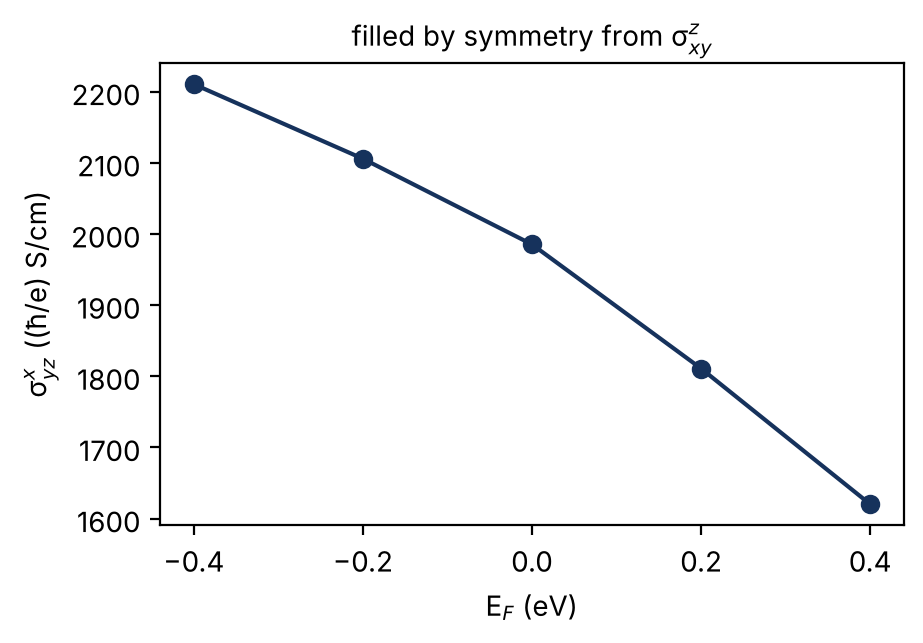

In [4]:
scan = read_postw90_shc(f"{KB}/Pt_postw90/Pt-shc-fermiscan.dat", win=f"{KB}/Pt_postw90/Pt.win")
fit = st.fit(scan[0.0])
print(format_fit(st, fit, unit="(ħ/e) S/cm"))
efs = sorted(scan); vals = [st.fit(scan[e])["full"][0 * 9 + 1 * 3 + 2] for e in efs]
fig, ax = plt.subplots(figsize=(4.8, 3)); ax.plot(efs, vals, "o-", color="#16325c")
ax.set_xlabel("E$_F$ (eV)"); ax.set_ylabel("σ$^x_{yz}$ ((ħ/e) S/cm)"); ax.set_title("filled by symmetry from σ$^z_{xy}$", fontsize=10)

## 2. Import with a symmetry check: anomalous Hall of bcc Fe ($\mathbf m\parallel z$)

The toy postw90 file contains small forbidden $\sigma_{yz},\sigma_{zx}$ (as from an unconverged k mesh or a wrong frame):

In [5]:
stc = SymTensor.from_analysis(analyze_tensors(f"{KB}/Fe_postw90", tensors="charge", ossg="no"), "charge", parts=("odd",))
f2 = stc.fit(read_postw90_ahc(f"{KB}/Fe_postw90/Fe-ahc-fermiscan.dat")[0.0])
print(format_fit(stc, f2, unit="S/cm"))

  full tensor σ_ij (S/cm):
    [           0         751.6             0 ]
    [      -751.6             0             0 ]
    [           0             0             0 ]
  independent parameters: σ_xy = 751.6
  symmetry violation of the input: 0.266 %
  WARNING non-zero components that symmetry forbids: σ_yz, σ_zy, σ_zx, σ_xz (frame / convergence?)


## 3. Built-in Kubo solver — analytic checks

**Haldane model** (honeycomb, $t_1=1$, $t_2=0.1$, $\phi=\pi/2$): $|\sigma_{xy}|=e^2/h$ in the topological gap, 0 for a large sublattice mass $M$.
**Kane–Mele** ($S_z$ conserved): quantised spin Hall $|\sigma^z_{xy}|=(\hbar/e)\,e^2/h$, no charge Hall.

Kane–Mele at E_F = 0: σ^z_xy, σ_xy = [ 1. -0.]


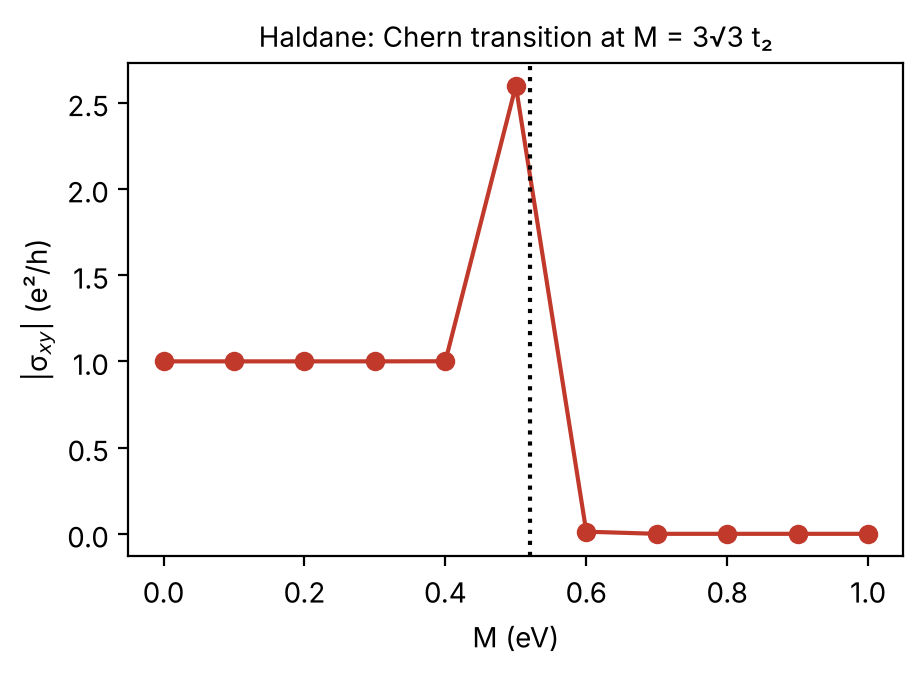

In [6]:
Ms = np.linspace(0, 1.0, 11)
sx = [abs(haldane(M=m)[0]) for m in Ms]
fig, ax = plt.subplots(figsize=(5, 3.2)); ax.plot(Ms, sx, "o-", color="#c0392b")
ax.axvline(3 * math.sqrt(3) * 0.1, ls=":", color="k"); ax.set_xlabel("M (eV)"); ax.set_ylabel("|σ$_{xy}$| (e²/h)")
ax.set_title("Haldane: Chern transition at M = 3√3 t₂", fontsize=10)
print("Kane–Mele at E_F = 0: σ^z_xy, σ_xy =", np.round(kane_mele()[0], 6))

Units in 3D: stacking Haldane layers with spacing $c=5$ Å must give $(e^2/h)/c$:

In [7]:
lat3 = lat.copy(); lat3[2, 2] = 5.0; R, H = haldane_hr()
s3 = KuboTB(lat3, R, H, centres=frac @ lat3, dims=3).conductivity([("charge", 0, 0, 1)], [0.0], (60, 60, 1), 1e-6)[0, 0]
print(f"σ_xy = {s3:.3f} S/cm;  (e²/h)/c = {3.874045865e-5 / 5e-8:.3f} S/cm")

σ_xy = 774.809 S/cm;  (e²/h)/c = 774.809 S/cm


## 4. Symmetry-driven Kubo run on a Wannier Hamiltonian

`examples/kubo/Graphene_KaneMele` holds the model as a Wannier90 `kane_mele_hr.dat` + `centres.xyz`. SymPhase computes only the
**pivot** components of the allowed tensor (P6/mmm1′: 3 independent), fills the rest by symmetry, and verifies one **non-pivot**
component with an independent Kubo evaluation:

In [8]:
d = f"{KB}/Graphene_KaneMele"
stg = SymTensor.from_analysis(analyze_tensors(d, tensors="spin", ossg="no"), "spin", parts=("even",))
R, H = read_hr(f"{d}/kane_mele_hr.dat")
model = KuboTB(read_poscar(f"{d}/POSCAR")["lattice"], R, H, centres=read_centres(f"{d}/centres.xyz"), dims=2, spin_order="blocks")
for fit in compute_symmetric(model, stg, [0.0, 0.5], n=(60, 60), eta=1e-6):
    print(f"E_F = {fit['E_F']} eV"); print(format_fit(stg, fit, unit="(ħ/e) e²/h")); print()

E_F = 0.0 eV
  σ^z_ij ((ħ/e) e²/h):
    [           0             1             0 ]
    [          -1             0             0 ]
    [           0             0             0 ]
  independent parameters: σ^x_yz = 0, σ^x_zy = 0, σ^z_xy = 1
  symmetry violation of the input: 0 %
  check σ^z_yx: computed -1, from symmetry -1  (rel. error 1.1e-13 %)

E_F = 0.5 eV
  σ^z_ij ((ħ/e) e²/h):
    [           0       0.59126             0 ]
    [    -0.59126             0             0 ]
    [           0             0             0 ]
  independent parameters: σ^x_yz = 0, σ^x_zy = 0, σ^z_xy = 0.59126
  symmetry violation of the input: 0 %
  check σ^z_yx: computed -0.59126, from symmetry -0.59126  (rel. error 3.9e-13 %)



## 5. Command line
```bash
symphase kubo plan    -d examples/kubo/Pt_postw90 --kind spin
symphase kubo import  -d examples/kubo/Pt_postw90 --kind spin --shc Pt_postw90/Pt-shc-fermiscan.dat --win Pt_postw90/Pt.win --ef 0
symphase kubo import  -d examples/kubo/Fe_postw90 --kind charge --part odd --ahc Fe_postw90/Fe-ahc-fermiscan.dat --ef 0
symphase kubo import  -d MyMaterial --kind orbital --table ohc_components.txt     # any code: 'σ^z_xy 1234.5' lines
symphase kubo compute -d examples/kubo/Graphene_KaneMele --kind spin --hr .../kane_mele_hr.dat --centres .../centres.xyz \
                      --spin-order blocks --dims 2 --grid 60 60
```
The built-in solver uses the tight-binding convention (Wannier centres, no position-matrix `r.dat` terms) and the intrinsic
(Fermi-sea, Berry-type) formula: T-odd spin and T-even charge components need Fermi-surface (∝ 1/Γ) or Boltzmann codes.